In [57]:
import matplotlib.pyplot as plt
import sklearn
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix , classification_report, roc_auc_score

In [58]:
# Needed functions

def read(name):
    return pd.read_csv(f"dataset/{name}.csv", na_values=["\\N"])

def lap_milliseconds(t):
    if pd.isna(t) or ":" not in str(t):
        return np.nan
    minutes, seconds = str(t).split(":")
    return int(minutes) * 60 * 1000 + float(seconds) * 1000

In [59]:
# reading dataset

races = read("races")
results = read("results")
qualifying = read("qualifying")
drivers = read("drivers")
circuits = read("circuits")
constructors_standings = read("constructor_standings")
constructors = read("constructors")
sprints = read("sprint_results")
driver_standings = read("driver_standings")

# we will only choose races from 2014 until present
# because this period is hybrid engines period and much more usable
races = races[races["raceId"] > 899]
results = results[results["raceId"].isin(races["raceId"])]
qualifying = qualifying[qualifying["raceId"].isin(races["raceId"])]
constructors_standings = constructors_standings[constructors_standings["raceId"].isin(races["raceId"])]

# keeping needed columns
races = races[["raceId", "year", "round", "circuitId"]]
results = results[["raceId","driverId","constructorId","grid", "positionOrder"]]
qualifying = qualifying[[ "raceId", "driverId", "constructorId", "q1", "q2", "q3" ]]
constructors_standings = constructors_standings[["raceId", "constructorId", "points", "wins"]]
driver_standings = driver_standings[["raceId", "driverId", "points", "wins"]]

results = results.rename(columns={"positionOrder": "final_result", "grid": "race_grid"})
sprints = sprints.rename(columns={"positionOrder": "sprint_result", "grid": "sprint_grid"})
sprints = sprints[[ "raceId", "driverId", "constructorId", "sprint_grid", "sprint_result" ]]
driver_standings = driver_standings.rename(columns={"points": "driver_points", "wins": "driver_wins"})
constructors_standings = constructors_standings.rename(columns={"points": "constructor_points", "wins": "constructor_wins"})

In [60]:
# creating a single dataframe with all the needed information

df = (
    races
    .merge(results, on="raceId", how="left")
    .merge(
        qualifying,
        on=["raceId", "driverId", "constructorId"],
        how="left"
    )
    .merge(
        constructors_standings,
        on=["raceId", "constructorId"],
        how="left"
    )
    .merge(
        sprints,
        on=["raceId", "driverId", "constructorId"],
        how="left",
    )
    .merge(
        driver_standings,
        on=["raceId", "driverId"],
        how="left",
    )
)

# change laptime to milliseconds
df["q1"] = df["q1"].apply(lap_milliseconds)
df["q2"] = df["q2"].apply(lap_milliseconds)
df["q3"] = df["q3"].apply(lap_milliseconds)

# deal with nan or 0
df.dropna(subset=['driverId'], inplace = True)
df.dropna(subset=['constructorId'], inplace = True)
df.dropna(subset=['raceId'], inplace = True)

# race grid of 0 means start in the pit lane, so we will set it to the back of grid, same for nan values
df.loc[df["race_grid"] == 0, "race_grid"] = df["race_grid"].max()
df.loc[df["race_grid"].isna(), "race_grid"] = df["race_grid"].max()

df[["sprint_grid", "sprint_result"]] = df[["sprint_grid", "sprint_result"]].fillna(0)


for c in ["q1", "q2", "q3"]:
    fastest = df.groupby("raceId")[c].transform("min")
    df[c] = (fastest / df[c]).fillna(0)   # pole positon is 1 and others are less than 1, if no time set then 0


df["driverId"] = df["driverId"].astype("int")
df["constructorId"] = df["constructorId"].astype("int")
df["raceId"] = df["raceId"].astype("int")
df["race_grid"] = df["race_grid"].astype("int")
df["sprint_grid"] = df["sprint_grid"].astype("int")
df["sprint_result"] = df["sprint_result"].astype("int")
df["final_result"] = df["final_result"].astype("int")
df["podium"] = (df["final_result"] <= 3).astype("int")


# points up to that point of the season, we will use this as a feature to predict podiums
# wins are also upt to that season
df = df.sort_values(["year", "round"])
g = df.groupby(["driverId", "year"])
df["driver_points"] = g["driver_points"].shift(1).fillna(0).astype(int)
df["driver_wins"] = g["driver_wins"].shift(1).fillna(0).astype(int)

# because we have two driver per constructor we need to delete duplicates of constructorid and then shift 1
teams = df[["raceId", "year", "round", "constructorId", "constructor_points", "constructor_wins"]].drop_duplicates(["raceId", "constructorId"])
teams = teams.sort_values(["year", "round"])
g = teams.groupby(["constructorId", "year"])
teams["constructor_points"] = g["constructor_points"].shift(1).fillna(0).astype(int)
teams["constructor_wins"] = g["constructor_wins"].shift(1).fillna(0).astype(int)
df = df.drop(columns=["constructor_points", "constructor_wins"])
df = df.merge(teams[["raceId", "constructorId", "constructor_points", "constructor_wins"]],
              on=["raceId", "constructorId"], how="left")

# podiums won before show how many podiums the driver has won before that race
df = df.sort_values(["year", "round"])
df["podiums_won_before"] = (
    df.groupby(["driverId", "year"])["podium"].cumsum() - df["podium"]
)

df[["driverId", "round", "podium", "podiums_won_before"]].head(60)


,driverId,round,podium,podiums_won_before
0,3,1,1,0
1,825,1,1,0
2,18,1,1,0
3,4,1,0,0
4,822,1,0,0
5,807,1,0,0
6,8,1,0,0
7,818,1,0,0
8,826,1,0,0
9,815,1,0,0


In [61]:
X = df[["race_grid", "q1", "q2", "q3", "sprint_grid", "sprint_result", "driver_points", "driver_wins", "constructor_points", "constructor_wins", "podiums_won_before"]]
Y = df["podium"]

In [62]:
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split( X, Y,df.index, test_size=0.2, random_state=4)


In [71]:
# the best recall i could get for logistic regression was 60% with this model

model = make_pipeline(StandardScaler(), LogisticRegression(C = 0.5 ,penalty='l2', max_iter=1000))

model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("logistic regression: ")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))

logistic regression: 
[[ 90  73]
 [ 37 896]]
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       933
           1       0.71      0.55      0.62       163

    accuracy                           0.90      1096
   macro avg       0.82      0.76      0.78      1096
weighted avg       0.89      0.90      0.89      1096



e:\machine learning\projects\predict-f1-winner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [76]:
model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=0.5, gamma='scale'))
model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("svm:")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))

svm:
[[ 92  71]
 [ 39 894]]
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       933
           1       0.70      0.56      0.63       163

    accuracy                           0.90      1096
   macro avg       0.81      0.76      0.78      1096
weighted avg       0.89      0.90      0.90      1096



xgboost: 
[[140  23]
 [135 798]]
              precision    recall  f1-score   support

           0       0.97      0.86      0.91       933
           1       0.51      0.86      0.64       163

    accuracy                           0.86      1096
   macro avg       0.74      0.86      0.77      1096
weighted avg       0.90      0.86      0.87      1096

race_grid             0.412792
podiums_won_before    0.150202
q3                    0.149633
q2                    0.053355
constructor_points    0.048940
driver_points         0.039345
sprint_result         0.034630
constructor_wins      0.032611
driver_wins           0.030707
q1                    0.026108
sprint_grid           0.021677
dtype: float32


<Axes: title={'center': 'XGBoost feature importance'}>

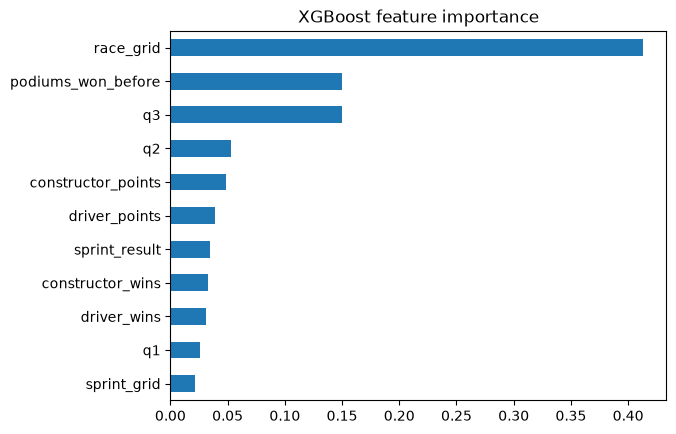

In [80]:
scale_of_classes = (y_train == 0).sum() / (y_train == 1).sum()

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_of_classes,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("xgboost: ")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))

importance = pd.Series(model.feature_importances_, index=X_train.columns)
print(importance.sort_values(ascending=False))

importance.sort_values().plot(kind="barh", title="XGBoost feature importance")

In [79]:
model = RandomForestClassifier(
    n_jobs = -1,
    max_depth = 3,
    min_samples_leaf = 3,
    n_estimators = 300,
    class_weight = "balanced",
    random_state=42,
    )
model.fit(X_train, y_train)
yhat = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Random Forest:")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))
print("ROC-AUC:", roc_auc_score(y_test, proba))


Random Forest:
[[143  20]
 [158 775]]
              precision    recall  f1-score   support

           0       0.97      0.83      0.90       933
           1       0.48      0.88      0.62       163

    accuracy                           0.84      1096
   macro avg       0.72      0.85      0.76      1096
weighted avg       0.90      0.84      0.86      1096

ROC-AUC: 0.9233063079057595
